#### Exploratory Data Analysis
Here I'll perform univariate, bivariate, multi variate and trend analysis to get the insights from the cleaned data.

#### Step-0: Setup

In [1]:
# Imports and load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the data with dates (parse_dates tells which columns are dates)
df=pd.read_csv("../data/cleaned/charging_clean.csv", parse_dates=['StartDatetime','EndDatetime'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72088 entries, 0 to 72087
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserID          72088 non-null  int64         
 1   ChargerID       72088 non-null  int64         
 2   ChargerCompany  72088 non-null  int64         
 3   Location        72088 non-null  object        
 4   ChargerType     72088 non-null  int64         
 5   StartDatetime   72088 non-null  datetime64[ns]
 6   EndDatetime     72088 non-null  datetime64[ns]
 7   Duration        72088 non-null  int64         
 8   Demand          72088 non-null  float64       
dtypes: datetime64[ns](2), float64(1), int64(5), object(1)
memory usage: 5.0+ MB


In [3]:
# Creating time columns (needed for few questions in the analysis)
df['Hour']=df['StartDatetime'].dt.hour
df['Month']=df['StartDatetime'].dt.month
df['Weekday']=df['StartDatetime'].dt.day_name()
df['Date']=df['StartDatetime'].dt.date
df['IsWeekend']=df['StartDatetime'].dt.day_of_week>=5
df.head()


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDatetime,EndDatetime,Duration,Demand,Hour,Month,Weekday,Date,IsWeekend
0,0,1,1,hotel,0,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,9,Thursday,2022-09-15,False
1,0,1,1,hotel,0,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,9,Wednesday,2022-09-14,False
2,0,1,1,hotel,0,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,9,Wednesday,2022-09-14,False
3,0,1,1,hotel,0,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,9,Thursday,2022-09-29,False
4,0,1,1,hotel,0,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,9,Sunday,2022-09-25,True


In [4]:
# Checking the no. of weekdays and weekends
df['IsWeekend'].value_counts()

IsWeekend
False    53356
True     18732
Name: count, dtype: int64

#### Step-1: Univariate analysis

> **Q1. How is charging demand distributed? Is it skewed, and are there any extremes?**


In [5]:
# Checking the distribution of demand column
df['Demand'].describe()

count    72088.000000
mean        17.569945
std         13.457859
min          0.010000
25%          7.697500
50%         14.260000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

In [6]:
# Checking the skewness of demand column
df['Demand'].skew()

np.float64(1.1955528223081422)

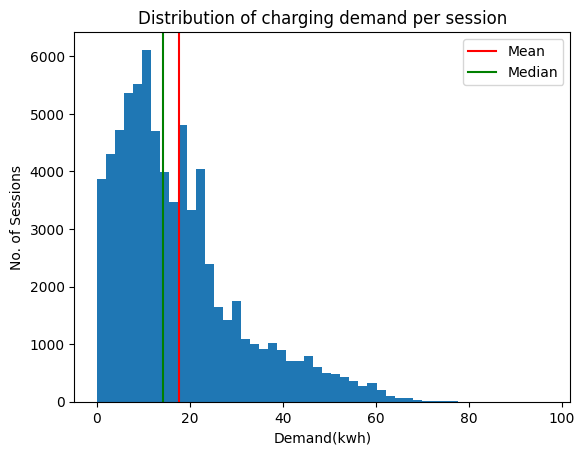

In [7]:
# Plotting the chart to check the demand distribution
plt.hist(df['Demand'],bins=50)
plt.axvline(df['Demand'].mean(), color='red', label='Mean')
plt.axvline(df['Demand'].median(), color='green', label='Median')
plt.title('Distribution of charging demand per session')
plt.xlabel('Demand(kwh)')
plt.ylabel('No. of Sessions')
plt.legend()
plt.show()

In [8]:
# Checking the mean percentage of demand for various ranges
(df['Demand']<1).mean()*100, (df['Demand']<=30).mean()*100, (df['Demand']>50).mean()*100

(np.float64(3.1447675063810894),
 np.float64(83.66857174564421),
 np.float64(3.444401287315503))

##### Observations:
1. Demand is rightly skewed (~1.2).
2. The median session uses 14.26 kwh and the mean is 17.56 kwh means a few large sessions pull the mean up.
3. Most sessions use 30kwh or less (83.66%) and only 3% use more than 50kwh.

> **Q2. How long do charging sessions usually last?**

In [9]:
# Checking the distribution of demand column
df['Duration'].describe()

count    72088.000000
mean       152.743688
std        146.354670
min          1.000000
25%         41.000000
50%        114.000000
75%        203.000000
max       1573.000000
Name: Duration, dtype: float64

In [10]:
# Checking the skewness of demand column
df['Duration'].skew()

np.float64(1.9222580875322377)

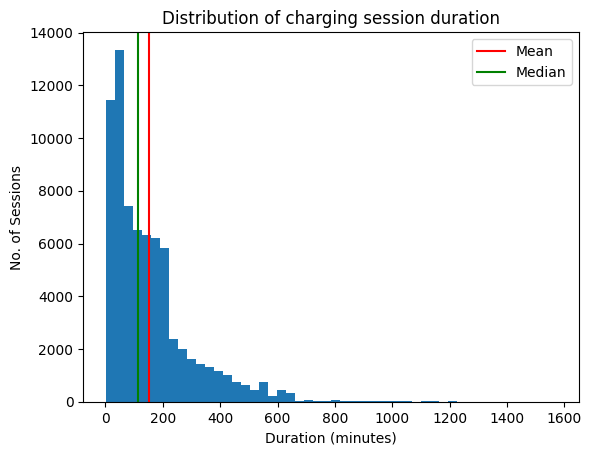

In [11]:
# Plotting the chart to check the demand distribution
plt.hist(df['Duration'],bins=50)
plt.axvline(df['Duration'].mean(), color='red', label='Mean')
plt.axvline(df['Duration'].median(), color='green', label='Median')
plt.title('Distribution of charging session duration')
plt.xlabel('Duration (minutes)')
plt.ylabel('No. of Sessions')
plt.legend()
plt.show()

In [12]:
# Checking the mean percentage of demand for various ranges (<1 hr, 1-4 hours, 4-8 hours, >8 hours)
(df['Duration']<=60).mean()*100, ((df['Duration']>60) & (df['Duration']<=240)).mean()*100, ((df['Duration']>240) & (df['Duration']<=480)).mean()*100, (df['Duration']>480).mean()*100

(np.float64(33.496559760292975),
 np.float64(48.0038286538675),
 np.float64(14.190988791477082),
 np.float64(4.308622794362446))

##### Observations:
1. Duration is rightly skewed (~1.9).
2. The median session last 114 minutes and the mean is 153 minutes means a few large sessions pull the mean up.
3. About 34% of sessions last up to 1 hour, 48% last 1–4 hours, 14% last 4–8 hours, and about 4% last more than 8 hours (up to about 26 hours).
4. Most people charge for a short stop or few hours. 
5. A small group of people leaves the car plugged in for a long time which is likely overnight charging at some locations which needs to be investigated.

> **Q3. Which locations, charger types and charger companies have the most sessions?**

Part-A: Location

In [13]:
# Session counts and percentage for each location
location_cnt= df['Location'].value_counts()
location_pct= df['Location'].value_counts(normalize=True)*100
location_table= pd.DataFrame({'Sessions': location_cnt, 'Percent': location_pct.round(1)})
location_table



,Sessions,Percent
Location,,
public area,13949,19.3
apartment,13908,19.3
resort,8714,12.1
hotel,8454,11.7
company,7526,10.4
public institution,6961,9.7
public parking lot,3364,4.7
market,2952,4.1
restaurant,2216,3.1


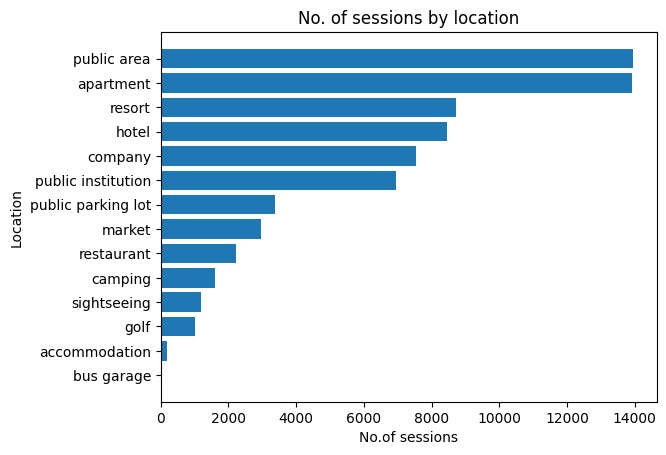

In [14]:
# Plotting chart for location wise session count and percentage.
location_cnt_sorted= location_cnt.sort_values()
plt.barh(location_cnt_sorted.index, location_cnt_sorted.values)
plt.title('No. of sessions by location')
plt.xlabel('No.of sessions')
plt.ylabel('Location')
plt.show()

Part-B: ChargerType

In [15]:
# Counting no.of sessions per charger type
charger_type_cnt= df['ChargerType'].value_counts()
charger_type_pct= df['ChargerType'].value_counts(normalize=True)*100
charger_type_table= pd.DataFrame({'Charger type count':charger_type_cnt,'Charger type pct':charger_type_pct})
charger_type_table

,Charger type count,Charger type pct
ChargerType,,
0,57384,79.602708
1,14704,20.397292


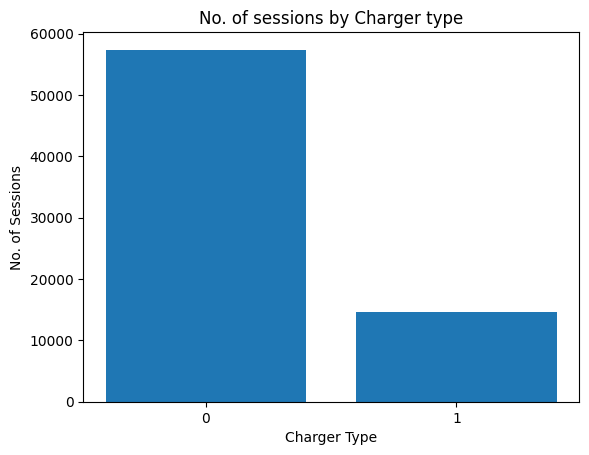

In [16]:
# plotting chart for no.of sessions by charger type
plt.bar(charger_type_cnt.index.astype(str),charger_type_cnt.values)
plt.title('No. of sessions by Charger type')
plt.xlabel('Charger Type')
plt.ylabel('No. of Sessions')
plt.show()

Part-C: Charger Company

In [17]:
# Counting No.of sessions by charger company
charger_cmp_cnt= df['ChargerCompany'].value_counts().sort_index()
charger_cmp_pct= df['ChargerCompany'].value_counts(normalize= True)*100
charger_cmp_table= pd.DataFrame({'Charger Company Count':charger_cmp_cnt,'Charger Company Pct':charger_cmp_pct})
charger_cmp_table

,Charger Company Count,Charger Company Pct
ChargerCompany,,
0,26839,37.230884
1,45249,62.769116


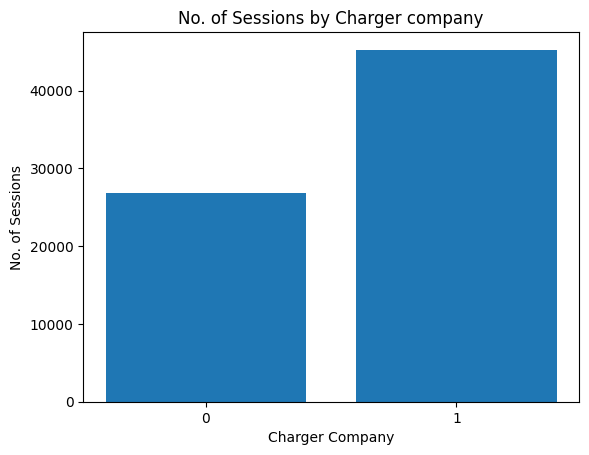

In [18]:
# Plotting chart for the No.of sessions by charger company
plt.bar(charger_cmp_cnt.index.astype(str), charger_cmp_cnt.values)
plt.title('No. of Sessions by Charger company')
plt.xlabel('Charger Company')
plt.ylabel('No. of Sessions')
plt.show()

#### Observations:
1. Public Areas and Apartments have the most sessions (together covers about 39% of overall) followed by resort, hotel, company, public institution with nearly 10-12% each. So these 6 locations cover about 82% of all sessions.
2. This means charging is concentrated in place where cars are parked for a long time and tourist places. 
2. About 80% of sessions use charger type 0 and 20% use type 1.
3. About 37% of sessions use charger company 0 and 63% use company 1.

#### Step-2: Bivariate Analysis

> **Q4. Which locations have the highest average demand per session?**


In [19]:
# Median demand by location with sessions counts
location_median= df.groupby('Location')['Demand'].median().sort_values(ascending=False)
location_demand= pd.DataFrame({'Median Demand':location_median,'Sessions':location_cnt})
location_demand

,Median Demand,Sessions
Location,,
accommodation,28.800,185
apartment,14.500,13908
bus garage,29.910,29
camping,23.650,1619
company,14.500,7526
golf,12.805,1026
hotel,12.120,8454
market,12.030,2952
public area,14.670,13949


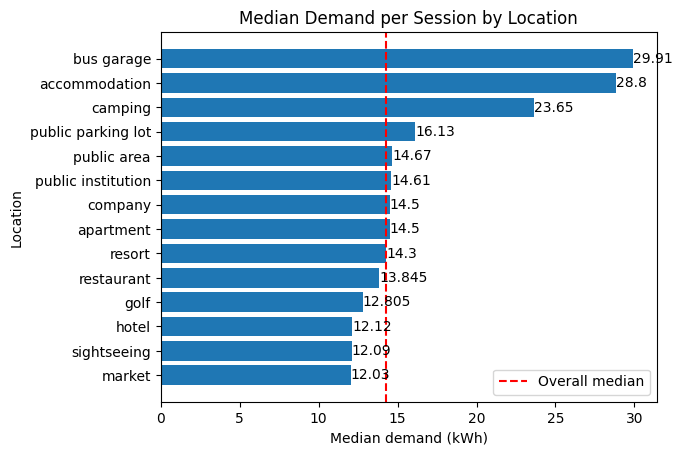

In [20]:
# Plotting chart for median demand
location_median_sorted= location_median.sort_values()
bars = plt.barh(location_median_sorted.index, location_median_sorted.values)
plt.bar_label(bars)
plt.axvline(df['Demand'].median(), color='red', linestyle='--', label='Overall median')
plt.title('Median Demand per Session by Location')
plt.xlabel('Median demand (kWh)')
plt.ylabel('Location')
plt.legend()
plt.show()

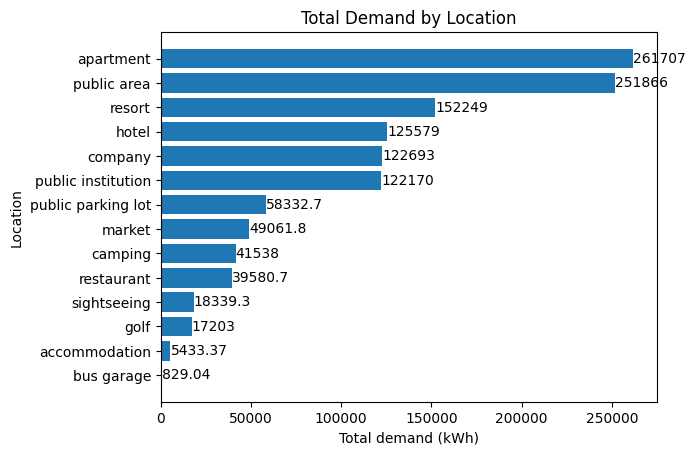

In [21]:
# Total demand per location
location_total= df.groupby('Location')['Demand'].sum().sort_values()
bars = plt.barh(location_total.index, location_total.values)
plt.bar_label(bars)
plt.title('Total Demand by Location')
plt.xlabel('Total demand (kWh)')
plt.ylabel('Location')
plt.show()

#### Observations:
1. Per session, bus garage (29.9 kWh), accommodation (28.8) and camping (23.7) have the highest median demand. Most other locations are close to the overall median of 14.3 kWh. Market, sightseeing and hotel are the lowest (about 12 kWh).
2. Bus garage is based on only 29 sessions and accommodation on 185, so these two results are less reliable.
3. In total demand, apartments (about 262k kWh) and public areas (about 252k kWh) are far ahead, because they have the most sessions.
4. So, places where people stay for long (camping, accommodation) use more energy per visit. 
5. Short stops like markets and sightseeing use less. 
6. But the total demand is high at apartments and public areas, so those are where more chargers or capacity will help most.

> **Q5. Does demand differ between charger types (0 vs 1) and charger companies (0 vs 1)?**

In [23]:
# Derive Power Column and compare by charger type
df['Power']= df['Demand']/(df['Duration']/60)
df.groupby('ChargerType')[['Demand', 'Duration', 'Power']].median()

,Demand,Duration,Power
ChargerType,,,
0,13.20,151.0,6.548954
1,17.34,37.0,32.790652


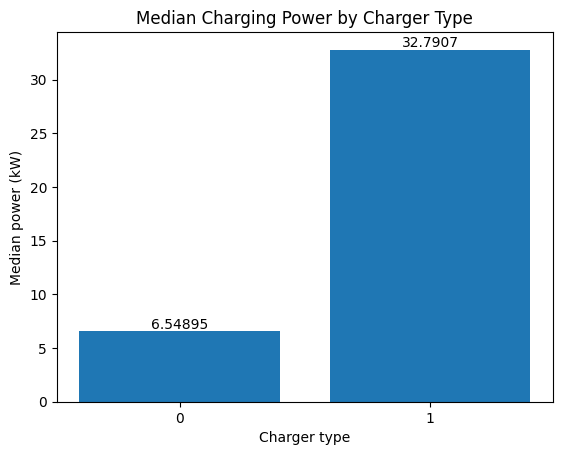

In [24]:
# Plotting charging power by charger type
type_power= df.groupby('ChargerType')['Power'].median()
bars= plt.bar(type_power.index.astype(str), type_power.values)
plt.bar_label(bars)
plt.title('Median Charging Power by Charger Type')
plt.xlabel('Charger type')
plt.ylabel('Median power (kW)')
plt.show()

In [25]:
# Comparison of demand by charger company
df.groupby('ChargerCompany')[['Demand', 'Duration', 'Power']].median()

,Demand,Duration,Power
ChargerCompany,,,
0,13.44,43.0,15.992308
1,14.79,152.0,6.607059


In [27]:
# Table showing how company and type are linked
pd.crosstab(df['ChargerType'], df['ChargerCompany'])

ChargerCompany,0,1
ChargerType,,
0,12135,45249
1,14704,0


#### Observations:
1. Type 1 sessions use more energy (median 17.3 vs 13.2 kWh) in much less time (37 vs 151 min), at about 33 kW vs 6.6 kW. 
2. All type 1 chargers belong to company 0.
3. It means type 1 is most likely a fast charger and type 0 a slow one.

> **Q6. Which hours of the day and days of the week have the most sessions and the highest demand?**


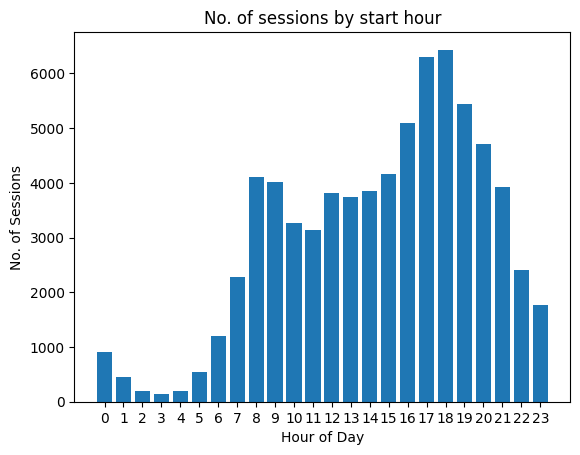

In [31]:
# Plotting No. of sessions per hour
hour_counts= df['Hour'].value_counts().sort_index()
plt.bar(hour_counts.index, hour_counts.values)
plt.title('No. of sessions by start hour')
plt.xlabel('Hour of Day')
plt.ylabel('No. of Sessions')
plt.xticks(range(0,24))
plt.show()

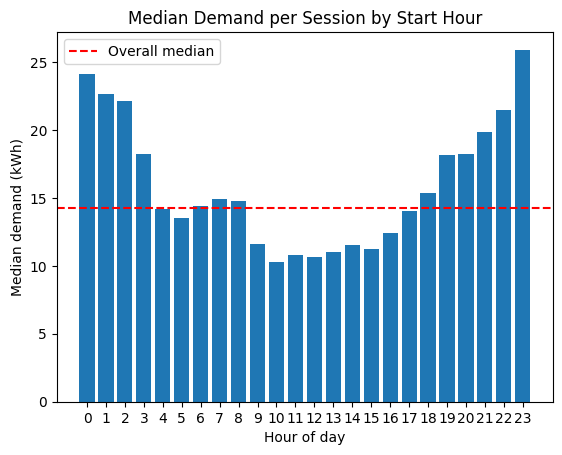

In [32]:
# Median demand per hour
hour_median = df.groupby('Hour')['Demand'].median()
plt.bar(hour_median.index, hour_median.values)
plt.axhline(df['Demand'].median(), color='red', linestyle='--', label='Overall median')
plt.title('Median Demand per Session by Start Hour')
plt.xlabel('Hour of day')
plt.ylabel('Median demand (kWh)')
plt.xticks(range(0, 24))
plt.legend()
plt.show()


In [33]:
# Weekday table
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = df['Weekday'].value_counts().reindex(day_order)
weekday_median = df.groupby('Weekday')['Demand'].median().reindex(day_order)
pd.DataFrame({'Sessions': weekday_counts, 'Median Demand': weekday_median})

,Sessions,Median Demand
Weekday,,
Monday,10228,14.19
Tuesday,10545,13.96
Wednesday,10777,14.29
Thursday,10931,14.53
Friday,10875,14.08
Saturday,9839,14.21
Sunday,8893,14.59


#### Observations:
1. Sessions peak at 5–6 pm, with a smaller peak at 8–9 am meaning chargers are busiest in the evening
2. Demand per session is highest for late-night starts (about 24–26 kWh) and lowest in late morning (about 10–11 kWh). 
3. Weekdays have more sessions than weekends, but median demand is almost the same every day.

> **Q7. How strongly is session duration related to demand?**

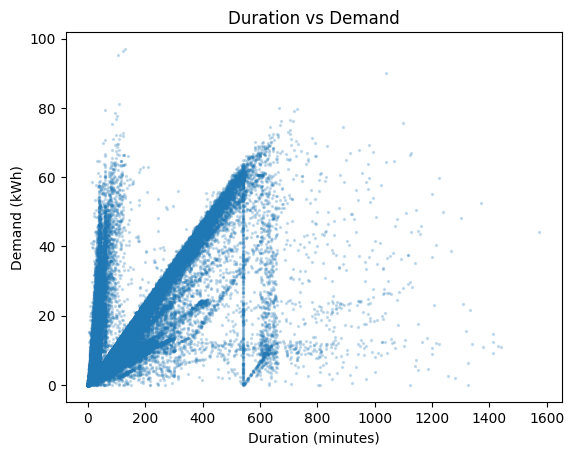

In [38]:
# Plotting scatter plot to compare duration and demand
plt.scatter(df['Duration'], df['Demand'], s=2, alpha=0.2)
plt.title('Duration vs Demand')
plt.xlabel('Duration (minutes)')
plt.ylabel('Demand (kWh)')
plt.show()

In [41]:
# Checking the correlation overall and by charger type
df['Duration'].corr(df['Demand']), df[df['ChargerType']==0]['Duration'].corr(df[df['ChargerType']==0]['Demand']),df[df['ChargerType']==1]['Duration'].corr(df[df['ChargerType']==1]['Demand'])

(np.float64(0.655237671234741),
 np.float64(0.7980830353881557),
 np.float64(0.46647118259640924))

#### Observations:
1. Duration and Demand have a strong positive correlation (0.66). 
2. It is stronger for slow chargers (0.80) than fast chargers (0.47). 
3. Demand rises with time for the first few hours, then flattens for very long sessions means longer sessions use more energy, until the battery is full; after that, the car just stays plugged in.

> **Q8. Do weekdays and weekends show different charging behaviour?**

In [44]:
# Weekday and weekend wise median demand and duration by session
df.groupby('IsWeekend')[['Demand', 'Duration']].median()

,Demand,Duration
IsWeekend,,
False,14.2,114.0
True,14.4,113.0


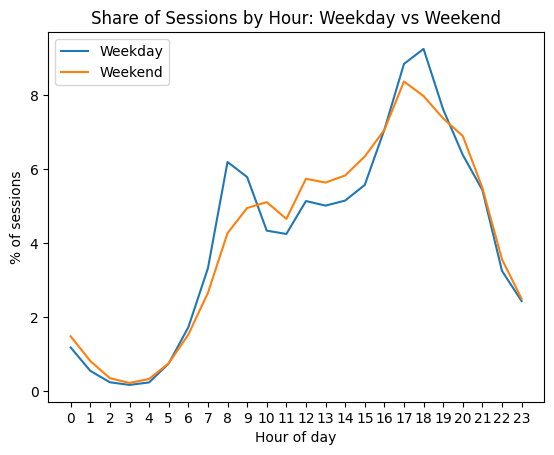

In [ ]:
# Plotting Weekday and weekend wise % of sessions by hour
hour_share = pd.crosstab(df['Hour'], df['IsWeekend'], normalize='columns')*100
plt.plot(hour_share.index, hour_share[False], label='Weekday')
plt.plot(hour_share.index, hour_share[True], label='Weekend')
plt.title('Share of Sessions by Hour: Weekday vs Weekend')
plt.xlabel('Hour of day')
plt.ylabel('% of sessions')
plt.xticks(range(0, 24))
plt.legend()
plt.show()

#### Observations: 
1. Median demand and duration are almost the same on weekdays and weekends. 
2. Weekday sessions peak in the morning and evening and weekend sessions are spread more across late morning and afternoon.
3. The amount of energy doesn't change, only the timing.